# Lab 2: Pre-Trained Word Embeddings

**Albert Kabore, PHD in AI.**

**AG News classification with averaged GloVe embeddings and a two-layer feed-forward network**

This submission explains the method in Part A, provides all eleven implementation steps in Part B, and interprets the results in Part C. It follows the workflow in the [Chapter 9 reference notebook](https://github.com/clulab/gentlenlp/blob/main/notebooks/chap09_classification.ipynb).

**Results provenance.** The numerical results and figures are retained from the supplied notebook's saved CPU run with seed 1234. This revision updates the explanations; it is not a new training run. The saved outputs report PyTorch 2.14.0+cpu, NumPy 2.3.4, and pandas 2.3.3. Data checks and recalculated metrics are documented separately in `REVIEW_NOTES.md`.

The code uses 300-dimensional GloVe 6B vectors, a 300-unit hidden layer, dropout of 0.3, an Adam learning rate of 0.001, batches of 500, and five epochs. An 80/20 stratified split gives 96,000 training and 24,000 development articles. The separate test file contains 7,600 articles. The hidden size and dropout differ from the reference notebook's 50 and 0.1; their effects have not been compared experimentally. This version also uses a custom GloVe loader, drops unknown tokens, and selects the checkpoint with the highest development accuracy.

**Running the notebook.** Install `torch numpy pandas tqdm nltk scikit-learn matplotlib jupyter`, then run the cells from top to bottom. The setup cell downloads missing AG News files and provides a GloVe reader. A local GloVe zip is used when available; an extracted file can be supplied through `LAB2_GLOVE_PATH`. `LAB2_DATA_DIR` can point to existing CSV files. The local zip is 862,182,613 bytes (about 822 MiB). The embedding matrix alone occupies about 480 MB before padding; temporary arrays and batches require additional memory. Runtime depends on the machine and download speed.

# Part A: Feed-Forward Neural Networks and Word Embeddings

This model assigns an AG News article to World, Sports, Business, or Sci/Tech using its title and description. The main challenge is turning variable-length text into a fixed-size input for a feed-forward neural network.

Pandas loads the CSV files. The preprocessing replaces backslashes with spaces, lowercases both text fields, and joins them. NLTK's `word_tokenize()` then separates the combined text into words and punctuation. Lowercasing aligns the input with the uncased GloVe 6B vocabulary.

Each known token maps to a 300-dimensional pre-trained GloVe vector. GloVe learns word representations from corpus-wide co-occurrence statistics (Pennington et al., 2014). These vectors provide information learned outside the labeled news dataset. This implementation drops tokens missing from the vocabulary, so it cannot use their information directly.

The token IDs are stored in a rectangular NumPy array. Shorter sequences receive a special padding ID whose embedding is all zeros. During the forward pass, the model sums the word vectors and divides by the number of non-padding tokens. This masked average gives every article a 300-dimensional representation. It preserves information about which words occur while discarding their order.

The document vector passes through a linear layer with 300 hidden units, a ReLU activation, and a linear output layer with four scores. Dropout of 0.3 is applied before both linear layers during training. The scores are raw logits. PyTorch's `CrossEntropyLoss` handles the log-softmax calculation internally, so the training code does not apply softmax first.

Adam updates the network using mini-batches of 500 and a learning rate of 0.001. The GloVe embeddings remain frozen; only the two linear layers, containing 91,504 parameters, are trained. After each of five epochs, development loss and accuracy are measured with dropout disabled. The checkpoint with the highest development accuracy is restored for final test evaluation. Accuracy, per-class precision, recall, F1, and a confusion matrix describe performance. These results characterize the saved run; they do not establish how performance varies across seeds or datasets.

*Part A: 319 words (whitespace count).*

---
# Part B: Model Implementation

## B.i Initialize the code: enable torch, numpy, pandas, and tqdm

In [1]:
import io
import os
import random
import shutil
import urllib.request
import zipfile
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm

import nltk
from nltk.tokenize import word_tokenize
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

# Register .progress_map / .progress_apply on pandas objects (tqdm progress bars).
tqdm.pandas()

# Reproducibility: seed every random number generator we use.
seed = 1234
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Use a GPU when one is available; otherwise fall back to the CPU.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'torch {torch.__version__} | numpy {np.__version__} | pandas {pd.__version__} | device: {device}')

torch 2.14.0+cpu | numpy 2.3.4 | pandas 2.3.3 | device: cpu


### Setup: obtain the data

Run this cell after B.i and before B.ii. It downloads missing AG News files and defines `open_glove()`. Downloads use a temporary `.part` file that is renamed after completion. The GloVe reader first checks for an extracted text file, then a local zip. It can try three download locations or use HTTP range requests to read a remote archive. The remote path depends on the server supporting byte-range requests. The saved run used a local zip; the fallback paths were not re-tested for this revision.

In [2]:
DATA_DIR = Path(os.environ.get('LAB2_DATA_DIR', 'data/ag_news_csv'))
GLOVE_PATH = Path(os.environ.get('LAB2_GLOVE_PATH', 'data/glove.6B.300d.txt'))

AG_NEWS_URL = 'https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/'
GLOVE_ZIP_URLS = [
    'https://nlp.stanford.edu/data/glove.6B.zip',
    'https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip',
    'https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip',
]

def download(url, dest):
    dest.parent.mkdir(parents=True, exist_ok=True)
    tmp = dest.with_name(dest.name + '.part')
    with urllib.request.urlopen(url, timeout=60) as response, open(tmp, 'wb') as f:
        total = int(response.headers.get('Content-Length', 0)) or None
        with tqdm(total=total, unit='B', unit_scale=True, desc=dest.name) as bar:
            while chunk := response.read(1 << 20):
                f.write(chunk)
                bar.update(len(chunk))
    tmp.replace(dest)

for name in ['train.csv', 'test.csv', 'classes.txt']:
    if not (DATA_DIR / name).exists():
        download(AG_NEWS_URL + name, DATA_DIR / name)

print('AG News:', sorted(p.name for p in DATA_DIR.iterdir()))


class HTTPRangeReader(io.RawIOBase):
    # Read-only, seekable view of a remote file; each read is one HTTP Range request.
    def __init__(self, url):
        self.url, self.pos = url, 0
        with urllib.request.urlopen(urllib.request.Request(url, headers={'Range': 'bytes=0-0'}), timeout=60) as r:
            self.size = int(r.headers['Content-Range'].split('/')[-1])

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.pos

    def seek(self, offset, whence=io.SEEK_SET):
        self.pos = {io.SEEK_SET: 0, io.SEEK_CUR: self.pos, io.SEEK_END: self.size}[whence] + offset
        return self.pos

    def readinto(self, buffer):
        if self.pos >= self.size:
            return 0
        end = min(self.pos + len(buffer), self.size) - 1
        request = urllib.request.Request(self.url, headers={'Range': f'bytes={self.pos}-{end}'})
        with urllib.request.urlopen(request, timeout=120) as r:
            data = r.read()
        buffer[:len(data)] = data
        self.pos += len(data)
        return len(data)


def open_glove():
    if GLOVE_PATH.exists():
        print('GloVe source: extracted file', GLOVE_PATH)
        return open(GLOVE_PATH, encoding='utf-8')
    zip_path = GLOVE_PATH.parent / 'glove.6B.zip'
    zip_path.parent.mkdir(parents=True, exist_ok=True)
    if not zip_path.exists() and shutil.disk_usage(zip_path.parent).free > 1.5e9:
        for url in GLOVE_ZIP_URLS:
            try:
                download(url, zip_path)
                break
            except Exception as e:
                print(f'Download from {url} failed ({e}); trying the next mirror.')
    if zip_path.exists():
        print('GloVe source: local zip', zip_path)
        zf = zipfile.ZipFile(zip_path)
    else:
        print('GloVe source: remote zip read with HTTP range requests (no local copy)', GLOVE_ZIP_URLS[-1])
        zf = zipfile.ZipFile(io.BufferedReader(HTTPRangeReader(GLOVE_ZIP_URLS[-1]), buffer_size=16 << 20))
    return io.TextIOWrapper(zf.open(GLOVE_PATH.name), encoding='utf-8')

AG News: ['classes.txt', 'test.csv', 'train.csv']


## B.ii Load the training dataset and take a quick look at it

The CSV files have no header row. Each row holds the class index (1-4), the title, and the description. `classes.txt` lists the class names, one per line, in index order.

In [3]:
classes = (DATA_DIR / 'classes.txt').read_text(encoding='utf-8').splitlines()
print('Classes:', classes)

column_names = ['class index', 'title', 'description']
train_df = pd.read_csv(DATA_DIR / 'train.csv', header=None, names=column_names)
print('Shape:', train_df.shape)
train_df.head()

Classes: ['World', 'Sports', 'Business', 'Sci/Tech']


Shape: (120000, 3)


,class index,title,description
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."


In [4]:
# Class balance: AG News has the same number of examples in every class.
counts = train_df['class index'].value_counts().sort_index()
pd.DataFrame({'class': classes, 'examples': counts.values}, index=counts.index)

,class,examples
class index,,
1,World,30000
2,Sports,30000
3,Business,30000
4,Sci/Tech,30000


## B.iii Replace backslashes with spaces using pandas `replace()`

Backslashes appear inside some descriptions, including `dwindling\band`. Replacing them with spaces separates the surrounding text. The function cleans both text columns, lowercases them, and joins them into a single `text` field to match the uncased GloVe vocabulary.

In [5]:
def clean_text(df):
    # The regex r'\\' matches one literal backslash.
    df[['title', 'description']] = df[['title', 'description']].replace(r'\\', ' ', regex=True)
    df['text'] = df['title'].str.lower() + ' ' + df['description'].str.lower()
    return df

has_backslash = train_df['description'].str.contains('\\', regex=False)
example_idx = has_backslash.idxmax()
print(f'Rows containing a backslash: {has_backslash.sum():,}')
print('Before:', train_df.loc[example_idx, 'description'])

train_df = clean_text(train_df)
print('After: ', train_df.loc[example_idx, 'description'])
print('Backslashes remaining:', int(train_df['text'].str.contains('\\', regex=False).sum()))

Rows containing a backslash: 12,522
Before: Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.


After:  Reuters - Short-sellers, Wall Street's dwindling band of ultra-cynics, are seeing green again.
Backslashes remaining: 0


## B.iv Tokenize the title and description with NLTK's `word_tokenize()`

The combined `text` column contains both required fields. As in the supplied reference notebook, `word_tokenize()` produces one token list per article from that column. `progress_map()` adds a tqdm progress bar. The NLTK setup checks for the `punkt_tab` resource before tokenizing.

In [6]:
try:
    nltk.data.find('tokenizers/punkt_tab')
except LookupError:
    nltk.download('punkt_tab', quiet=True)

def tokenize(df):
    df['tokens'] = df['text'].progress_map(word_tokenize)
    return df

train_df = tokenize(train_df)
train_df[['text', 'tokens']].head()

  0%|          | 0/120000 [00:00<?, ?it/s]

,text,tokens
0,wall st. bears claw back into the black (reute...,"[wall, st., bears, claw, back, into, the, blac..."
1,carlyle looks toward commercial aerospace (reu...,"[carlyle, looks, toward, commercial, aerospace..."
2,oil and economy cloud stocks' outlook (reuters...,"[oil, and, economy, cloud, stocks, ', outlook,..."
3,iraq halts oil exports from main southern pipe...,"[iraq, halts, oil, exports, from, main, southe..."
4,"oil prices soar to all-time record, posing new...","[oil, prices, soar, to, all-time, record, ,, p..."


## B.v Load the GloVe word embeddings

Each line of `glove.6B.300d.txt` holds a word followed by 300 floating-point numbers. We read it into a list of words (row index = word ID), a `word → ID` dictionary, and a `float32` matrix of shape `(400000, 300)`, which is about 480 MB.

In [7]:
def load_glove(lines):
    words, vectors = [], []
    for line in tqdm(lines, desc='Loading GloVe'):
        word, *values = line.rstrip().split(' ')
        words.append(word)
        vectors.append(np.asarray(values, dtype=np.float32))
    return words, np.stack(vectors)

with open_glove() as f:
    glove_words, glove_vectors = load_glove(f)
word_to_id = {word: i for i, word in enumerate(glove_words)}
print(f'Vocabulary: {len(glove_words):,} words | embedding matrix: {glove_vectors.shape}')

GloVe source: local zip data\glove.6B.zip


Loading GloVe: 0it [00:00, ?it/s]

Vocabulary: 400,000 words | embedding matrix: (400000, 300)


In [8]:
# Sanity check: nearest neighbors by cosine similarity show the semantic structure of the space.
unit_vectors = glove_vectors / np.linalg.norm(glove_vectors, axis=1, keepdims=True).clip(min=1e-8)

def most_similar(word, k=6):
    sims = unit_vectors @ unit_vectors[word_to_id[word]]
    best = np.argsort(-sims)[1:k + 1]  # skip the word itself
    return [(glove_words[i], round(float(sims[i]), 3)) for i in best]

for probe in ['football', 'economy', 'software', 'election']:
    if probe in word_to_id:
        print(f'{probe:>9}:', most_similar(probe))
del unit_vectors

 football: [('soccer', 0.768), ('basketball', 0.734), ('league', 0.66), ('baseball', 0.648), ('rugby', 0.643), ('hockey', 0.641)]
  economy: [('economic', 0.749), ('economies', 0.686), ('recession', 0.674), ('growth', 0.668), ('sector', 0.632), ('downturn', 0.617)]
 software: [('computer', 0.733), ('microsoft', 0.695), ('hardware', 0.658), ('computers', 0.623), ('internet', 0.598), ('server', 0.596)]
 election: [('elections', 0.899), ('electoral', 0.77), ('vote', 0.754), ('polls', 0.727), ('presidential', 0.711), ('candidate', 0.68)]


## B.vi Estimate tokenization coverage against GloVe

Type coverage counts distinct tokens; token coverage counts all occurrences. Both are measured on the original training file, before its train/development split. The figures describe vocabulary overlap and do not directly measure the effect of unknown words on classification accuracy.

In [9]:
token_counts = Counter(tok for tokens in train_df['tokens'] for tok in tokens)
n_types, n_tokens = len(token_counts), sum(token_counts.values())
known_types = sum(1 for tok in token_counts if tok in word_to_id)
known_tokens = sum(c for tok, c in token_counts.items() if tok in word_to_id)

print(f'Types  in GloVe: {known_types:,} / {n_types:,} = {known_types / n_types:.2%}')
print(f'Tokens in GloVe: {known_tokens:,} / {n_tokens:,} = {known_tokens / n_tokens:.2%}')

oov_counts = Counter({tok: c for tok, c in token_counts.items() if tok not in word_to_id})
print('\nMost frequent out-of-vocabulary tokens:')
pd.DataFrame(oov_counts.most_common(20), columns=['token', 'count']).T

Types  in GloVe: 64,652 / 88,122 = 73.37%
Tokens in GloVe: 5,211,697 / 5,275,725 = 98.79%

Most frequent out-of-vocabulary tokens:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
token,/b,href=,/a,//www.investor.reuters.com/fullquote.aspx,target=/stocks/quickinfo/fullquote,/p,newsfactor,cbs.mw,color=,/font,face=,size=,666666,//www.reuters.co.uk/financequotelookup.jhtml,qtype=sym,infotype=info,qcat=news,maccentral,-the,/strong
count,2984,2119,2117,1813,1813,537,510,471,431,417,416,416,416,242,242,242,242,214,213,184


## B.vii Add a zero-initialized padding embedding

We add a new vocabulary entry `<pad>` with ID 400,000 and an all-zeros vector. Padding positions therefore add nothing to the sum of embeddings, and in B.ix they are also excluded from the average.

In [10]:
pad_tok = '<pad>'
assert pad_tok not in word_to_id, 'pad token must be new'

pad_tok_id = len(glove_words)
glove_words.append(pad_tok)
word_to_id[pad_tok] = pad_tok_id
glove_vectors = np.vstack([glove_vectors, np.zeros((1, glove_vectors.shape[1]), dtype=np.float32)])

print(f'pad token id: {pad_tok_id} | new matrix shape: {glove_vectors.shape}')
print('pad vector is all zeros:', not glove_vectors[pad_tok_id].any())

pad token id: 400000 | new matrix shape: (400001, 300)
pad vector is all zeros: True


## B.viii Build 2-D token-ID and 1-D gold-label NumPy arrays

Known tokens map to GloVe IDs; unknown tokens are omitted. Each sequence is right-padded to the longest known-token sequence in that file. Labels shift from 1-4 to 0-3. A stratified split reserves 20% of the original training file for development evaluation. The array width is computed before this split, but no development labels or fitted text statistics are used to create the embeddings.

In [11]:
def to_token_ids(tokens):
    return [word_to_id[tok] for tok in tokens if tok in word_to_id]

def to_arrays(df):
    ids = df['tokens'].progress_map(to_token_ids)
    max_len = ids.map(len).max()
    X = np.full((len(ids), max_len), pad_tok_id, dtype=np.int64)
    for row, seq in enumerate(ids):
        X[row, :len(seq)] = seq
    y = df['class index'].to_numpy(dtype=np.int64) - 1
    return X, y

X, y = to_arrays(train_df)
print(f'X: {X.shape} {X.dtype} | y: {y.shape} {y.dtype} | labels: {np.unique(y)}')
print('First row (truncated):', X[0, :15], '...')

X_train, X_dev, y_train, y_dev = train_test_split(
    X, y, train_size=0.8, stratify=y, random_state=seed)
print(f'train: {X_train.shape} | dev: {X_dev.shape}')

  0%|          | 0/120000 [00:00<?, ?it/s]

X: (120000, 212) int64 | y: (120000,) int64 | labels: [0 1 2 3]
First row (truncated): [ 1015   829  4509 21844   137    75     0   521    23 10851    24 10851
    11     1  1015] ...
train: (96000, 212) | dev: (24000, 212)


## B.ix Construct a two-layer feed-forward neural network in PyTorch

* `nn.Embedding.from_pretrained(..., freeze=True, padding_idx=pad_tok_id)` holds the GloVe matrix as a non-trainable lookup table.
* `forward` embeds each token, averages over the real tokens only (the pad mask is used to count them), and sends the 300-d document vector through **Linear(300→300) → ReLU → Linear(300→4)**, with dropout before each linear layer.
* The network returns raw logits. `CrossEntropyLoss` applies log-softmax internally.

In [12]:
class FFNNTextClassifier(nn.Module):
    def __init__(self, vectors, pad_id, hidden_dim, output_dim, dropout):
        super().__init__()
        self.pad_id = pad_id
        self.embs = nn.Embedding.from_pretrained(
            torch.as_tensor(vectors), freeze=True, padding_idx=pad_id)
        emb_dim = vectors.shape[1]
        self.layers = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(emb_dim, hidden_dim),   # layer 1
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, output_dim),  # layer 2
        )

    def forward(self, x):
        mask = (x != self.pad_id).unsqueeze(-1).float()  # (batch, seq, 1)
        lengths = mask.sum(dim=1).clamp(min=1)             # avoid /0 for all-OOV docs
        doc_vectors = (self.embs(x) * mask).sum(dim=1) / lengths
        return self.layers(doc_vectors)

# Hyperparameters
hidden_dim = 300
output_dim = len(classes)
dropout = 0.3
lr = 1e-3
weight_decay = 0
batch_size = 500
n_epochs = 5

model = FFNNTextClassifier(glove_vectors, pad_tok_id, hidden_dim, output_dim, dropout).to(device)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen = sum(p.numel() for p in model.parameters() if not p.requires_grad)
print(model)
print(f'trainable parameters: {trainable:,} | frozen (GloVe) parameters: {frozen:,}')

FFNNTextClassifier(
  (embs): Embedding(400001, 300, padding_idx=400000)
  (layers): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=300, out_features=300, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=300, out_features=4, bias=True)
  )
)
trainable parameters: 91,504 | frozen (GloVe) parameters: 120,000,300


## B.x Train and evaluate development loss and accuracy after each epoch

Training uses shuffled mini-batches with dropout enabled. Development evaluation uses fixed end-of-epoch weights with dropout disabled and no gradient tracking. All five epochs run; the checkpoint with the highest development accuracy is restored afterward.

In [13]:
train_loader = DataLoader(TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
                          batch_size=batch_size, shuffle=True)
dev_loader = DataLoader(TensorDataset(torch.from_numpy(X_dev), torch.from_numpy(y_dev)),
                        batch_size=batch_size)

loss_func = nn.CrossEntropyLoss()
optimizer = optim.Adam((p for p in model.parameters() if p.requires_grad),
                       lr=lr, weight_decay=weight_decay)

def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, seen = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for X_batch, y_batch in tqdm(loader, desc='train' if train else 'dev', leave=False):
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)
            loss = loss_func(logits, y_batch)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y_batch)
            correct += (logits.argmax(dim=1) == y_batch).sum().item()
            seen += len(y_batch)
    return total_loss / seen, correct / seen

history = []
best_dev_acc, best_state = -1.0, None
for epoch in range(1, n_epochs + 1):
    train_loss, train_acc = run_epoch(train_loader, train=True)
    dev_loss, dev_acc = run_epoch(dev_loader, train=False)
    history.append(dict(epoch=epoch, train_loss=train_loss, train_acc=train_acc,
                        dev_loss=dev_loss, dev_acc=dev_acc))
    print(f'epoch {epoch}: train loss {train_loss:.4f} acc {train_acc:.4f} | '
          f'dev loss {dev_loss:.4f} acc {dev_acc:.4f}')
    if dev_acc > best_dev_acc:
        best_dev_acc = dev_acc
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)
history_df = pd.DataFrame(history).set_index('epoch')
print(f'\nBest dev accuracy: {best_dev_acc:.4f} (epoch {history_df["dev_acc"].idxmax()})')

train:   0%|          | 0/192 [00:00<?, ?it/s]

dev:   0%|          | 0/48 [00:00<?, ?it/s]

epoch 1: train loss 0.5118 acc 0.8421 | dev loss 0.3339 acc 0.8940


train:   0%|          | 0/192 [00:00<?, ?it/s]

dev:   0%|          | 0/48 [00:00<?, ?it/s]

epoch 2: train loss 0.3602 acc 0.8768 | dev loss 0.3092 acc 0.8980


... (6 outputs left out)

train:   0%|          | 0/192 [00:00<?, ?it/s]

dev:   0%|          | 0/48 [00:00<?, ?it/s]

epoch 5: train loss 0.3292 acc 0.8837 | dev loss 0.2877 acc 0.9025



Best dev accuracy: 0.9025 (epoch 5)


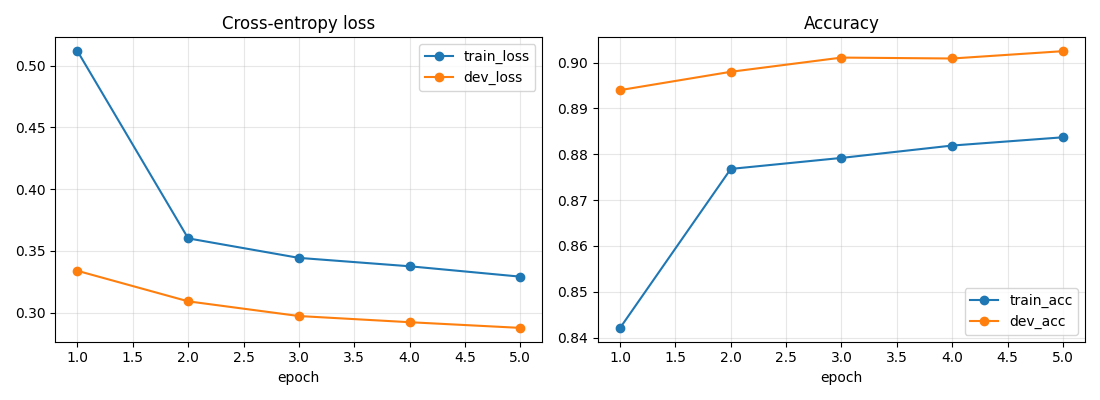

In [14]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))
history_df[['train_loss', 'dev_loss']].plot(ax=ax_loss, marker='o', title='Cross-entropy loss')
history_df[['train_acc', 'dev_acc']].plot(ax=ax_acc, marker='o', title='Accuracy')
for ax in (ax_loss, ax_acc):
    ax.set_xlabel('epoch')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## B.xi Evaluate on the test partition

The test file uses the same cleaning, tokenizer, GloVe vocabulary, and model. Its padding width is computed independently; masked averaging supports this different sequence length. The selected checkpoint produces test predictions, accuracy, per-class precision, recall, F1, and a confusion matrix.

In [15]:
test_df = pd.read_csv(DATA_DIR / 'test.csv', header=None, names=column_names)
test_df = tokenize(clean_text(test_df))
X_test, y_test = to_arrays(test_df)
print(f'X_test: {X_test.shape} | y_test: {y_test.shape}')

model.eval()
test_loader = DataLoader(TensorDataset(torch.from_numpy(X_test)), batch_size=batch_size)
with torch.no_grad():
    y_pred = np.concatenate([model(X_batch.to(device)).argmax(dim=1).cpu().numpy()
                             for (X_batch,) in test_loader])

test_acc = (y_pred == y_test).mean()
print(f'\nTest accuracy: {test_acc:.4f}\n')
print(classification_report(y_test, y_pred, labels=range(len(classes)), target_names=classes, digits=4))

  0%|          | 0/7600 [00:00<?, ?it/s]

  0%|          | 0/7600 [00:00<?, ?it/s]

X_test: (7600, 161) | y_test: (7600,)



Test accuracy: 0.8989

              precision    recall  f1-score   support

       World     0.9171    0.8847    0.9006      1900
      Sports     0.9512    0.9747    0.9628      1900
    Business     0.8523    0.8626    0.8574      1900
    Sci/Tech     0.8751    0.8737    0.8744      1900

    accuracy                         0.8989      7600
   macro avg     0.8989    0.8989    0.8988      7600
weighted avg     0.8989    0.8989    0.8988      7600



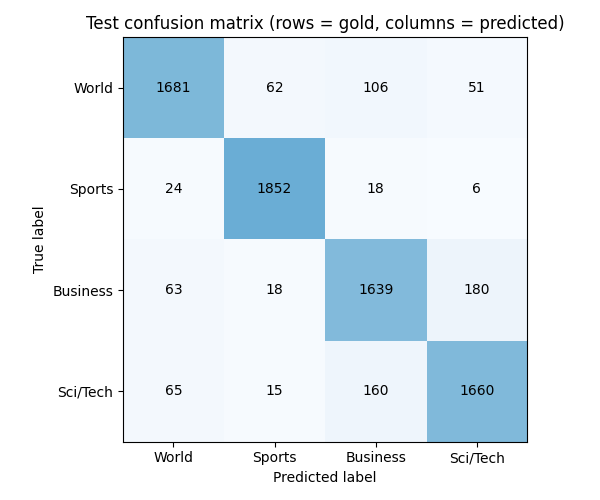

In [16]:
cm = confusion_matrix(y_test, y_pred, labels=range(len(classes)))
fig, ax = plt.subplots(figsize=(6, 5))
display = ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    ax=ax, cmap='Blues', colorbar=False, im_kw={'vmin': 0, 'vmax': 2 * cm.max()})
for label in display.text_.ravel():
    label.set_color('black')
ax.set_title('Test confusion matrix (rows = gold, columns = predicted)')
plt.tight_layout()
plt.show()

In [17]:
# Summary used in Part C: the most-confused class pair, and a few misclassified headlines.
off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
gold, pred = np.unravel_index(off_diag.argmax(), off_diag.shape)
per_class_acc = cm.diagonal() / cm.sum(axis=1).clip(min=1)

print(f'Best dev accuracy : {best_dev_acc:.4f}')
print(f'Test accuracy     : {test_acc:.4f}  (error rate {1 - test_acc:.2%})')
print('Per-class recall  :', {c: round(float(a), 4) for c, a in zip(classes, per_class_acc)})
if off_diag.any():
    print(f'Most common error : gold {classes[gold]} predicted as {classes[pred]} ({off_diag[gold, pred]} articles)')

errors = test_df.assign(gold=[classes[i] for i in y_test], predicted=[classes[i] for i in y_pred])
errors = errors[y_test != y_pred]
pd.set_option('display.max_colwidth', 120)
errors[['title', 'gold', 'predicted']].sample(min(10, len(errors)), random_state=seed)

Best dev accuracy : 0.9025
Test accuracy     : 0.8989  (error rate 10.11%)
Per-class recall  : {'World': 0.8847, 'Sports': 0.9747, 'Business': 0.8626, 'Sci/Tech': 0.8737}
Most common error : gold Business predicted as Sci/Tech (180 articles)


,title,gold,predicted
1938,British Music Fans Decry ITunes Pricing,Sci/Tech,Business
348,Unknown Nesterenko Makes World Headlines (Reuters),World,Sports
6203,Anil Ambani authorises mother to take decisions on his behalf,Business,World
3354,Nintendo to Unveil Handheld Upgrade,Business,Sci/Tech
2883,Witnesses to Confront Cali Cartel Kingpin,World,Business
2574,Adobe updates RAW plug-in with digital negative format,Business,Sci/Tech
3315,Analysis: Iran #39;s missile capabilities,World,Sci/Tech
6278,Update: PeopleSoft board won't negotiate Oracle takeover,Sci/Tech,Business
7505,Boys 'cured' with gene therapy,World,Sci/Tech
1509,Oracle case bounces to Europe,Sci/Tech,Business


---
# Part C: Analysis

## C.1 How the commands in Part B work

**B.i Initialization.** NumPy handles arrays, pandas handles tables, PyTorch supplies tensors and neural-network operations, and tqdm displays progress. `tqdm.pandas()` registers `progress_map()` and related methods. Seeds control the random generators used for initialization, dropout, shuffling, and splitting. They support repeatability in a fixed environment, but do not guarantee identical results across hardware or software versions ([PyTorch reproducibility documentation](https://docs.pytorch.org/docs/2.14/notes/randomness.html)). `device` chooses CUDA when available; the saved run used the CPU.

**B.ii Loading and inspecting data.** `pd.read_csv(..., header=None, names=...)` reads the headerless CSV with explicit column names. `head()` previews articles, while `shape` and `value_counts()` check size and label balance. `classes.txt` supplies the class names in index order. The training file contains 120,000 rows, with 30,000 per class. This agrees with the dataset statistics in Zhang et al. (2015, Table 3). Class balance makes accuracy useful, while the per-class metrics reveal differences it can hide.

**B.iii Backslash replacement.** `df[['title', 'description']].replace(r'\\', ' ', regex=True)` replaces literal backslashes inside both text columns. The raw-string regular expression uses two backslashes to match one literal backslash. The saved example changes `dwindling\band` to `dwindling band`. There were 12,522 training descriptions containing a backslash; none remain in the cleaned combined text. `.str.lower()` and string concatenation then produce one lowercased `text` column ([pandas documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.replace.html)).

**B.iv Tokenization.** `progress_map(word_tokenize)` applies NLTK's tokenizer to each article. Both required fields are covered because `text` contains the title and description; the supplied Chapter 9 notebook follows this approach too. NLTK combines sentence segmentation with an improved Treebank word tokenizer, separating punctuation and splitting contractions such as `don't` into `do` and `n't`. The setup checks for `punkt_tab` and downloads it if missing ([NLTK documentation](https://www.nltk.org/api/nltk.tokenize.html)).

**B.v GloVe loading.** `open_glove()` supplies a text stream from a local text file, a local zip, or a download. The loader reads each word and its 300 values, converts the values to `float32`, and stacks the rows. `word_to_id` connects each word to its row. The resulting matrix has shape `(400000, 300)`. The optional nearest-neighbor check uses cosine similarity to inspect the vectors; it is not a classifier evaluation. The original GloVe 6B release is uncased and was trained on Wikipedia 2014 and Gigaword 5 ([Stanford GloVe repository](https://github.com/stanfordnlp/GloVe)).

**B.vi Vocabulary coverage.** `Counter` counts token occurrences. Type coverage measures the fraction of distinct tokens present in GloVe: 64,652 / 88,122 = 73.37%. Token coverage weights by frequency: 5,211,697 / 5,275,725 = 98.79%. This means 64,028 token occurrences are unmatched. The contrast shows that unmatched types are relatively infrequent. The frequent unmatched items include HTML fragments, URLs, and source names. High coverage does not establish that dropping them has no effect; rare names or technical terms may still matter.

**B.vii Padding.** `np.vstack()` appends an all-zero vector and assigns it the new ID 400,000. The assertion checks that `<pad>` does not replace an existing entry. The model excludes padding from both the summed vectors and the token count. Its embedding layer also receives `padding_idx=pad_tok_id`. All embeddings are frozen in this implementation ([PyTorch embedding documentation](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Embedding.html)).

**B.viii Arrays and development split.** `to_token_ids()` keeps known tokens and looks up their IDs. `np.full()` allocates an `int64` array filled with the padding ID, and each sequence is copied into its row. Training inputs have shape `(120000, 212)`; labels have shape `(120000,)`. Subtracting one converts labels 1-4 to the 0-3 range required by the loss function. `train_test_split(..., stratify=y, random_state=seed)` preserves class proportions in the 96,000/24,000 train/development split ([scikit-learn split documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)).

**B.ix Two-layer network.** `nn.Embedding.from_pretrained(..., freeze=True)` performs the word-vector lookup. In `forward()`, the mask identifies non-padding positions; summing along the sequence and dividing by the masked count produces the document mean. `clamp(min=1)` prevents division by zero if no known tokens remain. The mean passes through Dropout, Linear(300, 300), ReLU, Dropout, and Linear(300, 4). The two linear layers contain 300 x 300 + 300 + 300 x 4 + 4 = 91,504 trainable parameters. The embedding table contains 120,000,300 frozen values after padding.

**B.x Training and development evaluation.** `TensorDataset` and `DataLoader` create batches. For each training batch, the model computes logits, cross-entropy measures the loss, `zero_grad()` clears earlier gradients, `backward()` computes gradients, and `optimizer.step()` updates the trainable weights. Multiplying each batch's mean loss by its size gives an example-weighted epoch average. Development evaluation disables dropout and gradient tracking. The code runs all five epochs and restores the checkpoint with the highest development accuracy. This is checkpoint selection; it does not stop training early ([PyTorch loss documentation](https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html)).

**B.xi Testing.** The test file uses the same cleaning, tokenization, vocabulary, and masked averaging. Its array has shape `(7600, 161)`: padding width is computed separately for each file, which this model can handle because averaging removes the sequence dimension. Under `model.eval()` and `torch.no_grad()`, `argmax()` selects the largest logit. Precision measures how often a predicted class is correct; recall measures the fraction of that class recovered; F1 is their harmonic mean. `classification_report()` and the confusion matrix summarize these outcomes ([scikit-learn metrics documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html)).

## C.2 Interpretation of the test results

The results below describe the saved run. Recalculating metrics from the submitted confusion matrix confirms their arithmetic consistency; it does not independently reproduce the model's predictions.

**Overall performance.** The model correctly classified 6,832 of 7,600 test articles, giving 89.89% accuracy and a 10.11% error rate. Macro-F1 was 0.8988. An always-one-class prediction would obtain 25% accuracy on this balanced test set. The best development accuracy was 90.25% at epoch 5, approximately 0.36 percentage points above the test accuracy. The scores are close, but one run cannot establish that the development partition represents every future sample or that model selection introduced no overfitting.

**Learning behavior.** Development loss declined across the five epochs, while development accuracy improved overall with a small dip at epoch 4.

| Epoch | Training loss | Training accuracy | Development loss | Development accuracy |
|---|---|---|---|---|
| 1 | 0.5118 | 84.21% | 0.3339 | 89.40% |
| 2 | 0.3602 | 87.68% | 0.3092 | 89.80% |
| 3 | 0.3444 | 87.92% | 0.2973 | 90.11% |
| 4 | 0.3376 | 88.19% | 0.2923 | 90.09% |
| 5 | 0.3292 | 88.37% | 0.2877 | 90.25% |

Training accuracy is lower than development accuracy, but the two measurements use different conditions. Training includes dropout and averages predictions made while weights are changing. Development evaluation uses the end-of-epoch weights with dropout disabled. The development curve shows no rise in loss over these five epochs. It does not rule out overfitting, and it does not establish that additional epochs would improve test performance.

**Differences between classes.**

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| World | 0.9171 | 0.8847 | 0.9006 | 1,900 |
| Sports | 0.9512 | 0.9747 | 0.9628 | 1,900 |
| Business | 0.8523 | 0.8626 | 0.8574 | 1,900 |
| Sci/Tech | 0.8751 | 0.8737 | 0.8744 | 1,900 |
| Macro average | 0.8989 | 0.8989 | 0.8988 | 7,600 |

Sports has the highest F1 in this run; Business has the lowest. Sports recall of 0.9747 means that 1,852 of its 1,900 articles were recovered. Business recall of 0.8626 corresponds to 1,639 of 1,900. Equal test support makes the macro and support-weighted averages identical before rounding, but it does not make performance equal across classes.

| Gold / Predicted | World | Sports | Business | Sci/Tech |
|---|---|---|---|---|
| World | 1,681 | 62 | 106 | 51 |
| Sports | 24 | 1,852 | 18 | 6 |
| Business | 63 | 18 | 1,639 | 180 |
| Sci/Tech | 65 | 15 | 160 | 1,660 |

Business was predicted as Sci/Tech 180 times, and Sci/Tech as Business 160 times. Together, these account for 340 of 768 errors, or 44.27%. This is the largest combined confusion between two classes. Stories about technology companies can contain both business and technology content, which is a plausible explanation for the overlap. The confusion matrix alone does not establish why the model made each decision.

**Inspecting individual mistakes.** The saved sample includes iTunes pricing and Oracle/PeopleSoft takeover stories labeled Sci/Tech but predicted Business. Their content spans the two categories. It also includes an Olympic sprint story labeled World and predicted Sports, and a gene-therapy story labeled World and predicted Sci/Tech. Those examples raise questions about category boundaries or individual annotations; they do not confirm incorrect gold labels. All benchmark labels remain unchanged. A sample of ten mistakes cannot estimate the prevalence of labeling errors across the dataset.

**Limits and next experiments.** This is one saved training run with one seed, five epochs, and fixed hyperparameters. No experiment here isolates the benefit of pre-training, measures the impact of dropping unknown tokens, or compares the chosen hidden size and dropout with the reference settings. Averaging discards word order, and some HTML artifacts remain. Useful follow-up experiments would compare HTML cleanup, an unknown-token representation, embedding fine-tuning, and a phrase-aware baseline using the same development protocol. Repeating training across seeds would measure run-to-run variability. These are proposals, not results.

---
## References

- clulab. (n.d.). *Chapter 9: Multiclass text classification with feed-forward neural networks and word embeddings* [Jupyter notebook]. [Reference notebook](https://github.com/clulab/gentlenlp/blob/main/notebooks/chap09_classification.ipynb).
- Pennington, J., Socher, R., & Manning, C. D. (2014). GloVe: Global vectors for word representation. *Proceedings of EMNLP*, 1532-1543. [Paper](https://aclanthology.org/D14-1162/). Pre-trained release details: [Stanford GloVe repository](https://github.com/stanfordnlp/GloVe).
- Zhang, X., Zhao, J., & LeCun, Y. (2015). Character-level convolutional networks for text classification. *Advances in Neural Information Processing Systems, 28*. [Paper; dataset statistics in Table 3](https://arxiv.org/abs/1509.01626). CSV copy used by the code: [CharCnn_Keras AG News files](https://github.com/mhjabreel/CharCnn_Keras/tree/master/data/ag_news_csv).
- NLTK project. (n.d.). *nltk.tokenize package*. [Tokenizer documentation](https://www.nltk.org/api/nltk.tokenize.html).
- pandas development team. (n.d.). *pandas.read_csv* and *pandas.DataFrame.replace*. [CSV reader](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html); [replacement](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.replace.html).
- PyTorch contributors. (n.d.). *PyTorch 2.14 documentation*. [Embedding](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Embedding.html); [CrossEntropyLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html); [reproducibility](https://docs.pytorch.org/docs/2.14/notes/randomness.html).
- scikit-learn developers. (n.d.). *scikit-learn documentation*. [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html); [classification_report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html).
- Python Software Foundation. (n.d.). *Python 3 standard library documentation*. Download and archive helpers: [urllib.request](https://docs.python.org/3/library/urllib.request.html); [zipfile](https://docs.python.org/3/library/zipfile.html); [io](https://docs.python.org/3/library/io.html).

In [ ]:
from IPython.display import HTML, display
display(HTML('<style>\n.jp-Notebook, #notebook-container, .jp-Cell, .cell,\n.jp-RenderedHTMLCommon, .jp-RenderedText, .text_cell_render,\n.rendered_html, .input_area, .output_area, .highlight {\n    color: #000000 !important;\n    background-color: #ffffff !important;\n}\n.jp-Notebook *, #notebook-container *, .jp-Cell *, .cell *,\n.jp-RenderedHTMLCommon *, .jp-RenderedText *, .text_cell_render *,\n.rendered_html *, .input_area *, .output_area *, .highlight *,\n.cm-editor .cm-content *, .cm-s-jupyter * {\n    color: #000000 !important;\n    -webkit-text-fill-color: #000000 !important;\n    text-shadow: none !important;\n}\n.jp-Notebook a, .rendered_html a, .text_cell_render a {\n    color: #000000 !important;\n    text-decoration: underline;\n}\n</style>'))